In [1]:
!nvidia-smi

Sun Nov  1 14:02:49 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
DATASET_URL = "https://github.com/11325017-ship-it/yolov5-mask-detection-colab/releases/download/v1/Face.Mask.Detection.v1i.yolov5pytorch.zip"
SAVE_DIR = "/content/drive/MyDrive/yolov5_mask/runs"

In [4]:
!git clone --depth 1 https://github.com/ultralytics/yolov5

Cloning into 'yolov5'...
remote: Enumerating objects: 164, done.
remote: Counting objects: 100% (164/164), done.
remote: Compressing objects: 100% (143/143), done.
remote: Total 164 (delta 48), reused 58 (delta 20), pack-reused 0 (from 0)
Receiving objects: 100% (164/164), 984.05 KiB | 14.06 MiB/s, done.
Resolving deltas: 100% (48/48), done.


In [5]:
%cd yolov5
%pip install -q -r requirements.txt

/content/yolov5


In [6]:
from pathlib import Path
import yaml, zipfile

In [24]:
!wget -q --show-progress -O /content/mask_dataset.zip {DATASET_URL}

# 使用手動上傳
# from google.colab import files
# uploaded = files.upload()
# !cp "{next(iter(uploaded))}" /content/mask_dataset.zip

/content/mask_datas 100%[===================>]  52.21M   184MB/s    in 0.3s    


In [8]:
with zipfile.ZipFile("/content/mask_dataset.zip") as z:
    z.extractall("/content/dataset")

In [9]:
src_yaml = next(Path("/content/dataset").rglob("data.yaml"))
root = src_yaml.parent
names = yaml.safe_load(src_yaml.read_text())["names"]


In [10]:
cfg = {"path": str(root),
      "train": "train/images",
      "val": "valid/images",
      "names": names}
Path("data/mask.yaml").write_text(yaml.dump(cfg, allow_unicode=True))

119

In [11]:
print(cfg)

{'path': '/content/dataset', 'train': 'train/images', 'val': 'valid/images', 'names': ['mask_weared_incorrect', 'with_mask', 'without_mask']}


In [18]:
!python train.py --img 640 --batch-size 16 --epochs 50 --data data/mask.yaml \
    --weights yolov5s.pt --project {SAVE_DIR} --name mask --exist-ok

WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1793542133.223419    4438 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout) 
wandb: WARNING W&B disabled due to login timeout.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
train: weights=yolov5s.pt, cfg=, data=data/mask.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=50, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=None, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, project=/content/drive/M

In [19]:
from IPython.display import Image, display

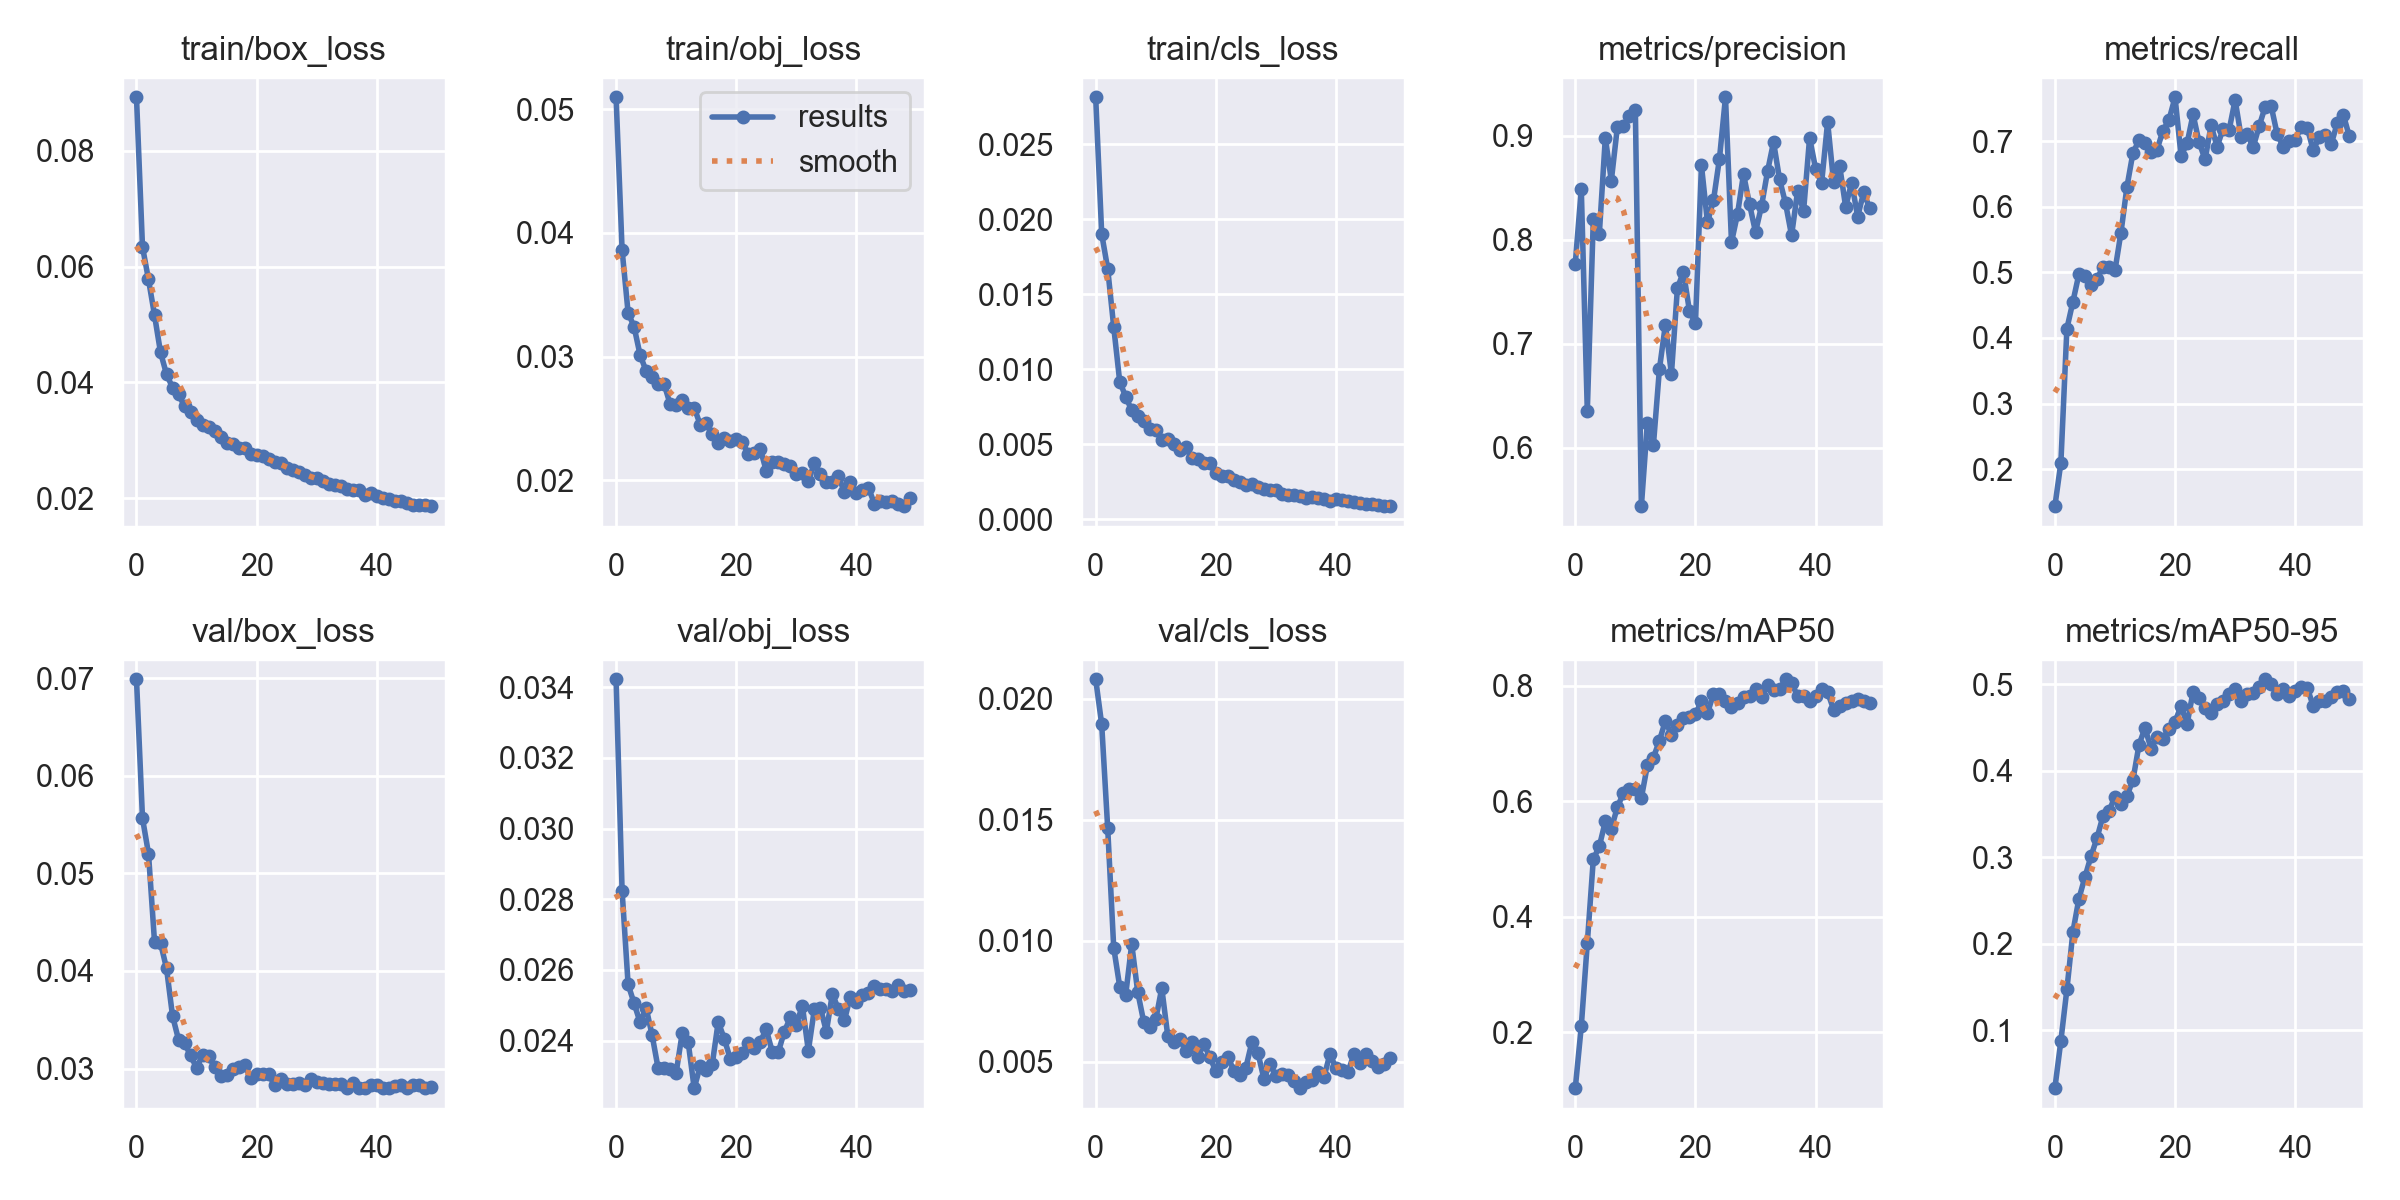

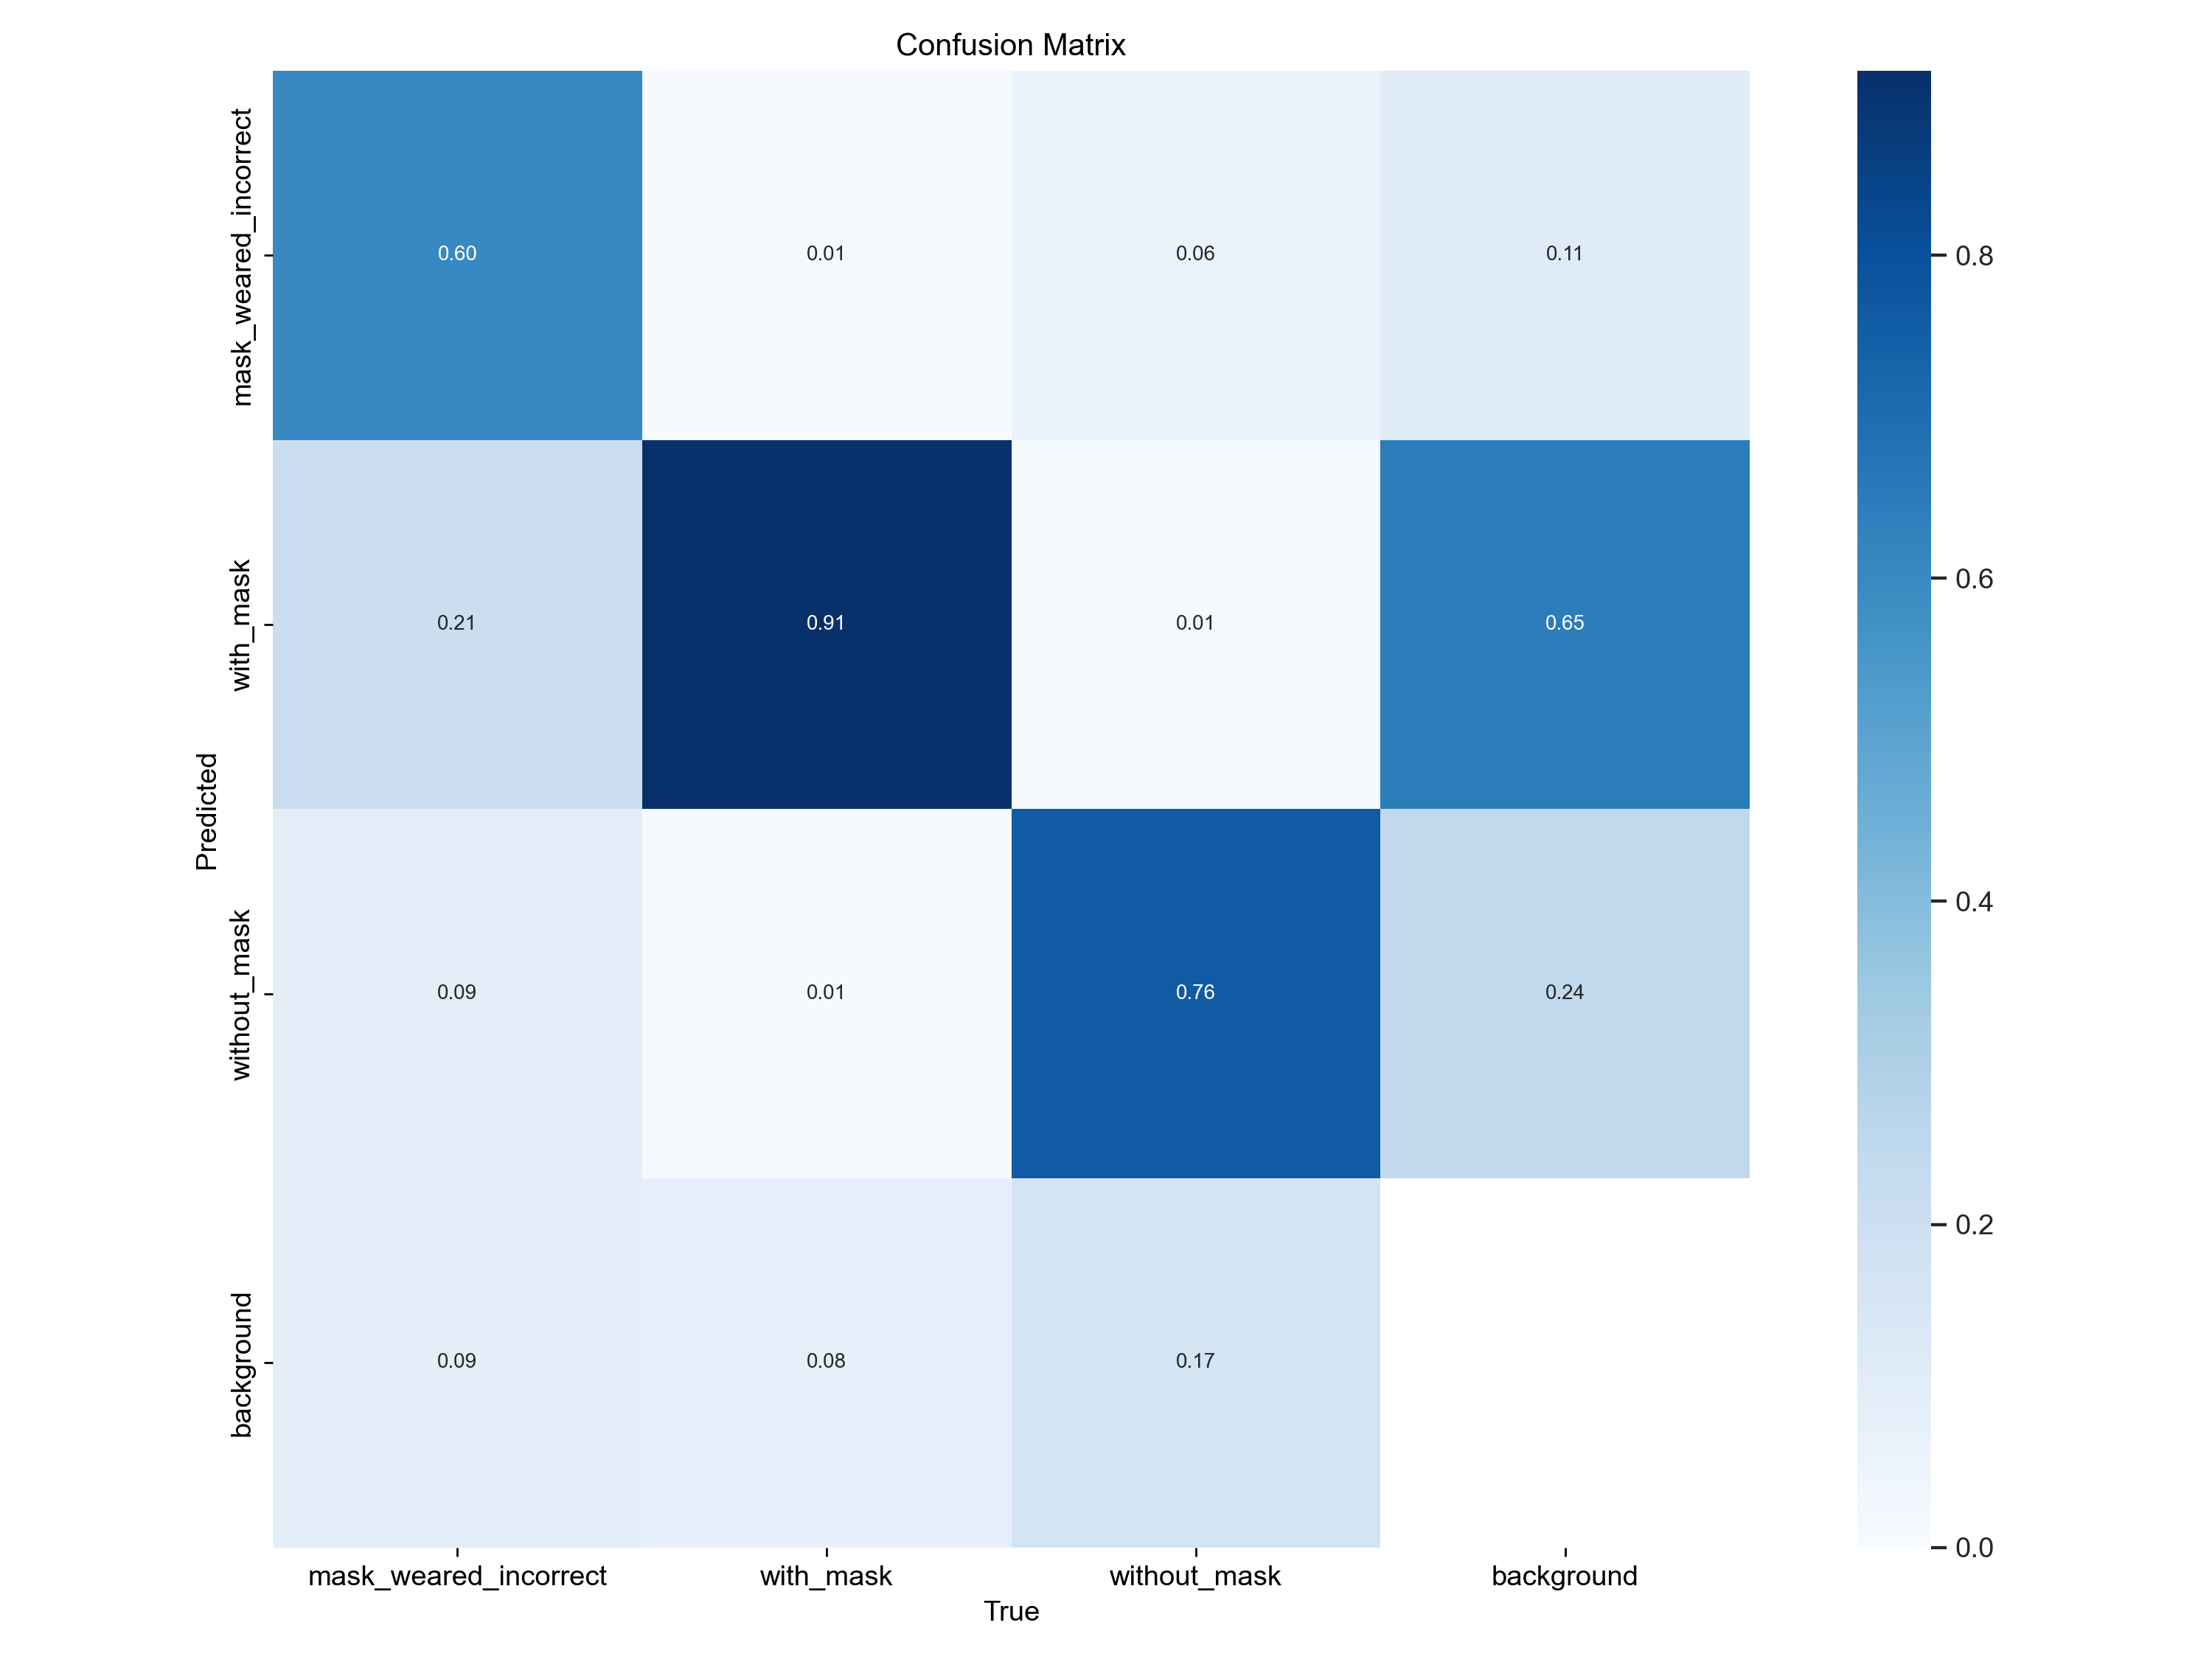

In [20]:
display(Image(f"{SAVE_DIR}/mask/results.png"))
display(Image(f"{SAVE_DIR}/mask/confusion_matrix.png"))

In [21]:
!python detect.py --weights {SAVE_DIR}/mask/weights/best.pt \
    --source {root}/valid/images --img 640 --conf-thres 0.4 --name mask_detect --exist-ok

detect: weights=['/content/drive/MyDrive/yolov5_mask/runs/mask/weights/best.pt'], source=/content/dataset/valid/images, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.4, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=runs/detect, name=mask_detect, exist_ok=True, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 d248d20 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,018,216 parameters, 0 gradients, 15.8 GFLOPs
image 1/239 /content/dataset/valid/images/maksssksksss100_png.rf.895deabfe4834d592eecb1113d64fd17.jpg: 640x640 3 with_masks, 15.1ms
image 2/239 /content/dataset/valid/images/maksssksksss101_png.rf.fbd12a1ad10b58304ed5fe01318e87c7.jpg: 640x640 1 with_mask, 16.5ms
image 3/239 /content/dataset/va

In [22]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import glob

In [23]:
img_paths = sorted(glob.glob("runs/detect/mask_detect/*.jpg"))[:6]


fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.ravel()

for i, path in enumerate(img_paths):
    img = mpimg.imread(path)
    axes[i].imshow(img)
    axes[i].axis("off")
    axes[i].set_title(path.split("/")[-1], fontsize=10)

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

Saving TestImage2.jpeg to TestImage2.jpeg
detect: weights=['/content/drive/MyDrive/yolov5_mask/runs/mask/weights/best.pt'], source=/content/yolov5/TestImage2.jpeg, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.4, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=runs/detect, name=custom_detect, exist_ok=True, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 d248d20 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,018,216 parameters, 0 gradients, 15.8 GFLOPs
image 1/1 /content/yolov5/TestImage2.jpeg: 384x640 1 with_mask, 30.4ms
Speed: 0.5ms pre-process, 30.4ms inference, 62.6ms NMS per image at shape (1, 3, 640, 640)
Results saved to runs/detect/custom_detect


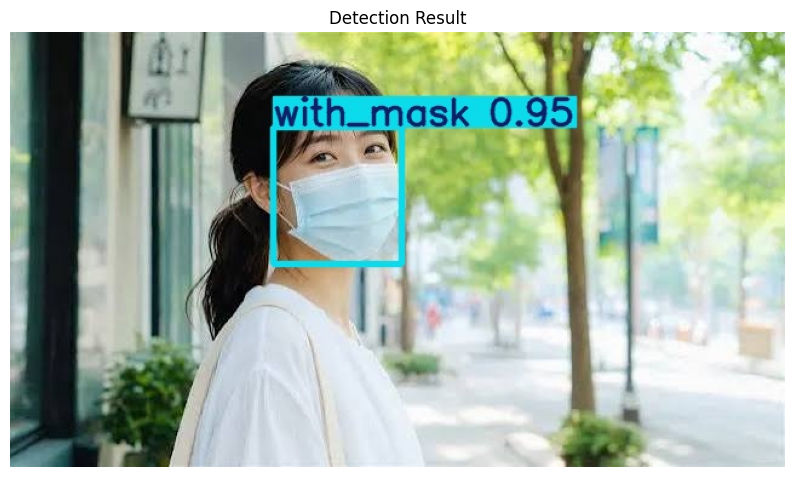

In [27]:
import os
from google.colab import files
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# 1. 讓使用者上傳圖片
uploaded = files.upload()
if uploaded:
    custom_img_name = next(iter(uploaded))
    # 使用 os.path.abspath 確保不論當前工作目錄在哪，都能正確取得上傳檔案的絕對路徑
    custom_img_path = os.path.abspath(custom_img_name)

    # 2. 執行 YOLOv5 偵測
    !python detect.py --weights {SAVE_DIR}/mask/weights/best.pt \
        --source "{custom_img_path}" --img 640 --conf-thres 0.4 --name custom_detect --exist-ok

    # 3. 顯示偵測結果
    detected_img_path = f"runs/detect/custom_detect/{custom_img_name}"
    if os.path.exists(detected_img_path):
        plt.figure(figsize=(10, 10))
        img = mpimg.imread(detected_img_path)
        plt.imshow(img)
        plt.axis("off")
        plt.title("Detection Result")
        plt.show()
    else:
        print("偵測失敗，未找到結果圖片。")